# DATA37711 HW2 Question 3

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import mean_squared_error
from dataloader import HW2Dataset
from models import RandomKitchenSinks, sweep_rks_model, MLP, mlp_sweep
from plotting import plot_surface_2d


ds = HW2Dataset.from_csv("train.csv", "val.csv", "test.csv")
X_train, y_train = ds.train.X, ds.train.y
X_val, y_val = ds.val.X, ds.val.y
X_test = ds.test.X
for name, split in [("Training", ds.train), ("Validation", ds.val), ("Test", ds.test)]:
    print(name, split.X.shape, None if split.y is None else split.y.shape)
    assert np.isfinite(split.X).all()
    if split.y is not None:
        assert np.isfinite(split.y).all()


Training (600, 2) (600,)
Validation (200, 2) (200,)
Test (200, 2) None


## (a) Training data visualization

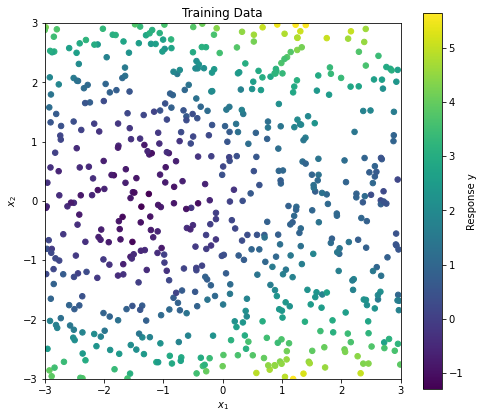

In [2]:
fig, ax = plt.subplots(figsize=(7, 6))
points = ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="viridis", s=30)
fig.colorbar(points, ax=ax, label="Response y")
ax.set(xlabel=r"$x_1$", ylabel=r"$x_2$", title="Training Data", xlim=(-3, 3), ylim=(-3, 3))
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig("q3a_training_data.png", dpi=300, bbox_inches="tight", facecolor="white", transparent=False)
plt.show()


## (b) RKS + ridge regression

In [3]:
import importlib
import inspect
import models

# Reload models.py from disk
importlib.invalidate_caches()
models = importlib.reload(models)

# Update the names previously imported into the notebook
RandomKitchenSinks = models.RandomKitchenSinks
sweep_rks_model = models.sweep_rks_model
MLP = models.MLP
mlp_sweep = models.mlp_sweep

print("Loaded file:", models.__file__)
print("Function signature:", inspect.signature(sweep_rks_model))

Loaded file: /Users/lydia/Desktop/DATA37711_FoundationsML/HW/hw2/models.py
Function signature: (sweep_values, X_train, y_train, X_val, y_val, parameter='D', D=512, sigma=1.0, ridge_lambda=0.001, random_state=42)


In [4]:
sigma_values = [0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0, 10.0]
best_rks, best_val_mse_rks, best_sigma_rks = sweep_rks_model(
    sigma_values, X_train, y_train, X_val, y_val,
    parameter="sigma", D=512, ridge_lambda=0.001, random_state=42
)
rks_results = best_rks.sweep_results_
print(rks_results.round(6).to_string(index=False))
print("Best sigma:", best_sigma_rks)
print("Selected validation MSE:", best_val_mse_rks)


 sigma  Train MSE  Validation MSE
  0.10   0.009004        0.251066
  0.20   0.015384        0.097412
  0.30   0.021000        0.054697
  0.50   0.027125        0.042482
  0.75   0.029144        0.041957
  1.00   0.030184        0.038702
  1.50   0.031373        0.037529
  2.00   0.032329        0.037142
  3.00   0.033108        0.036050
  5.00   0.036674        0.037589
 10.00   0.114324        0.121626
Best sigma: 3.0
Selected validation MSE: 0.036049644146563975


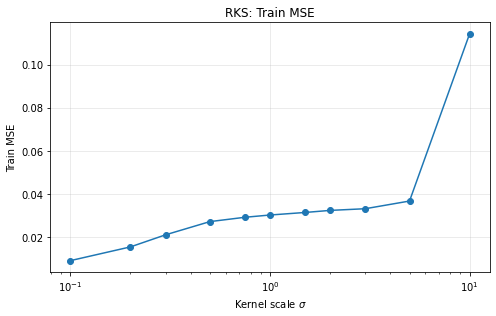

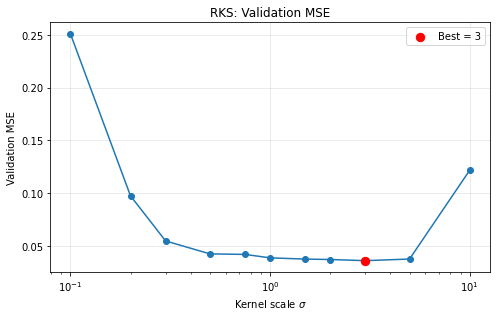

In [5]:
# Helper used for both sweeps; each loss gets its own plot.
def plot_sweep(results, column, xlabel, prefix, best_value, log_base):
    for metric, suffix in [("Train MSE", "training_mse"), ("Validation MSE", "validation_mse")]:
        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.plot(results[column], results[metric], marker="o")
        ax.set_xscale("log", base=log_base)
        if log_base == 2:
            ax.set_xticks(results[column])
            ax.set_xticklabels(results[column])
        if metric == "Validation MSE":
            loss = results.loc[results[column] == best_value, metric].iloc[0]
            ax.scatter(best_value, loss, color="red", s=70, zorder=3, label=f"Best = {best_value:g}")
            ax.legend()
        ax.set(xlabel=xlabel, ylabel=metric, title=f"{prefix}: {metric}")
        ax.grid(alpha=0.3)
        fig.tight_layout()
        filename = f"q3{'b_rks' if prefix == 'RKS' else 'c_mlp'}_{suffix}.png"
        fig.savefig(filename, dpi=300, bbox_inches="tight", facecolor="white", transparent=False)
        plt.show()

plot_sweep(rks_results, "sigma", r"Kernel scale $\sigma$", "RKS", best_sigma_rks, 10)


## (c) One-hidden-layer MLP


H=8: train=0.058495, validation=0.058789, best epoch=1394
H=16: train=0.037754, validation=0.044854, best epoch=3000
H=32: train=0.032150, validation=0.039457, best epoch=2130
H=64: train=0.031704, validation=0.039487, best epoch=1730
H=128: train=0.030071, validation=0.038888, best epoch=1944
H=256: train=0.031601, validation=0.038154, best epoch=1155
 Hidden width  Train MSE  Validation MSE  Best epoch  Epochs trained
            8   0.058495        0.058789        1394            1594
           16   0.037754        0.044854        3000            3000
           32   0.032150        0.039457        2130            2330
           64   0.031704        0.039487        1730            1930
          128   0.030071        0.038888        1944            2144
          256   0.031601        0.038154        1155            1355
Best hidden width: 256
Selected model best epoch: 1155
Selected model epochs trained: 1355
Selected validation MSE: 0.038153693079948425


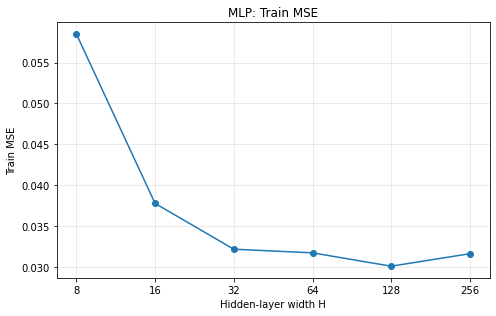

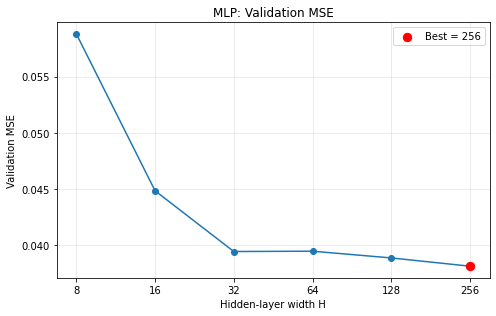

In [6]:
hidden_dims = [8, 16, 32, 64, 128, 256]
best_mlp, best_val_mse_mlp, best_hidden_dim_mlp = mlp_sweep(
    hidden_dims, X_train, y_train, X_val, y_val,
    lr=0.01, batch_size=64, num_epochs=3000, patience=200, seed=42
)
mlp_results = best_mlp.sweep_results_
print(mlp_results.round(6).to_string(index=False))
print("Best hidden width:", best_hidden_dim_mlp)
print("Selected model best epoch:", best_mlp.best_epoch_)
print("Selected model epochs trained:", best_mlp.epochs_trained_)
print("Selected validation MSE:", best_val_mse_mlp)
plot_sweep(mlp_results, "Hidden width", "Hidden-layer width H", "MLP", best_hidden_dim_mlp, 2)


## (d) Comparison, test predictions, and fitted surfaces

In [7]:
best_rks = RandomKitchenSinks(
    D=512, sigma=best_sigma_rks, ridge_lambda=0.001, random_state=42
).fit(X_train, y_train)

best_mlp = MLP(
    X_train.shape[1], d_hidden=best_hidden_dim_mlp,
    lr=0.01, batch_size=64, seed=42
).fit(X_train, y_train, X_val, y_val, num_epochs=3000, patience=200)

print(f"Refitted MLP best epoch: {best_mlp.best_epoch_}")

Refitted MLP best epoch: 1155


               Model  Training MSE  Validation MSE
         RKS + Ridge      0.033108        0.036050
One-hidden-layer MLP      0.031601        0.038154
Saved rks_test_predictions.csv: 200 rows, no header/index
Saved mlp_test_predictions.csv: 200 rows, no header/index


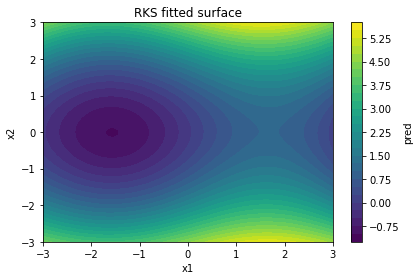

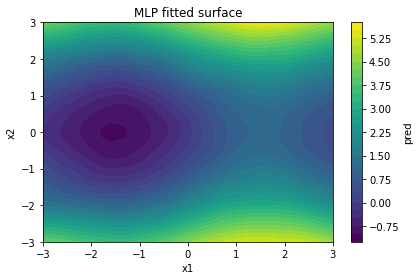

In [8]:
comparison = pd.DataFrame({
    "Model": ["RKS + Ridge", "One-hidden-layer MLP"],
    "Training MSE": [mean_squared_error(y_train, best_rks.predict(X_train)),
                     mean_squared_error(y_train, best_mlp.predict(X_train))],
    "Validation MSE": [mean_squared_error(y_val, best_rks.predict(X_val)),
                       mean_squared_error(y_val, best_mlp.predict(X_val))]
})
print(comparison.round(6).to_string(index=False))
for filename, model in [("rks_test_predictions.csv", best_rks),
                        ("mlp_test_predictions.csv", best_mlp)]:
    predictions = model.predict(X_test)
    assert predictions.shape == (len(X_test),)
    assert np.isfinite(predictions).all()
    np.savetxt(filename, predictions, delimiter=",")
    saved = np.loadtxt(filename, delimiter=",")
    assert saved.shape == (len(X_test),) and np.allclose(saved, predictions)
    print(f"Saved {filename}: {len(predictions)} rows, no header/index")

# Actual calls to the teacher's plotting helper.
plot_surface_2d(best_rks.predict, (-3, 3), (-3, 3),
                title="RKS fitted surface", filename="q3d_rks_plot.png")
plt.show()
plot_surface_2d(best_mlp, (-3, 3), (-3, 3),
                title="MLP fitted surface", filename="q3d_mlp_plot.png")
plt.show()
